# Image Evals Are Simpler Than You Think

If your product generates or edits images, OpenAI's [image evals cookbook](https://developers.openai.com/cookbook/examples/multimodal/image_evals) shows a sound way to grade them: hard gates first, then scores from 0 to 5, then tags for how an image failed. To run it, OpenAI built a custom harness of three packages that call the image model, save the images, and run the judge. Doing the same for your app usually means keeping an eval script like that next to it.

In this notebook, the grade is one more step on the table the images already live in. Mark an image ready, and the judge grades it and saves the grade next to the image. When you change the rubric and re-grade, only the grade runs again.

Each recipe starts from a new prompt or edit instruction, makes the image, and grades it.

- Recipe 1 grades an image made from a prompt.
- Recipe 2 shows the words read off a flyer and which required lines were found.
- Recipe 3 grades an edit made to one reference image.
- Recipe 4 grades an edit made from two reference images.
- Recipe 5 re-grades the images already made, with judge calls only and no image calls.

The checkout screen, the flyer, the logo, and the try-on are the examples the recipes run on.


## Setup

- Run this from the `simpler-img-evals` folder.
- Pick the `simpler-img-evals` kernel.
- Set `OPENAI_API_KEY` and `GEMINI_API_KEY` in your shell, then run `uv run pxt daemon restart` (see the README's setup).


In [1]:
!uv sync

Resolved 153 packages in 4ms
Audited 144 packages in 3ms


## Create the tables

Every recipe uses these tables. `pxt schema diff` shows the plan. `pxt schema update` applies it.


In [2]:
!pxt schema diff schema.py img_eval

= img_eval/generations     no change
= img_eval/edits           no change
= img_eval/gen_evals       no change
= img_eval/edit_evals      no change

Plan: 0 create, 0 update, 4 unchanged, 0 extra  |  0 destructive


In [3]:
!pxt schema update schema.py img_eval -f

catalog is up to date


## Recipe 1: Grade a generated image

You give it a prompt. You get the image, a pass or a fail, scores, and tags for how it failed.

The examples are a checkout screen and a flyer. The seed script makes the images and leaves them unmarked, so you can look at them first. Mark them ready, and only then does the judge run, and only then do you pay for it.


In [4]:
!python scripts/seed_demo.py


Connected to Pixeltable database at: postgresql+psycopg://postgres:***@/pixeltable?host=%2FUsers%2Falison-pxt%2F.pixeltable%2Fpgdata
generating 2 images with OpenAI and 2 edits with Gemini...
Inserted 2 rows with 0 errors in 28.76 s (0.07 rows/s)
Inserted 2 rows with 0 errors in 17.41 s (0.11 rows/s)
done. images are generated, eval_ready=False (not graded yet).
grade them in demo.ipynb, or:
  generations = pxt.get_table("img_eval/generations")
  generations.update({"eval_ready": True}, where=generations.batch_id == "demo_v1")
  pxt.get_table("img_eval/gen_evals").select(gen_evals.case_id, gen_evals.verdict).collect()


Connected to Pixeltable database at: postgresql+psycopg://postgres:***@/pixeltable?host=%2FUsers%2Falison-pxt%2F.pixeltable%2Fpgdata


/Users/alison-pxt/Documents/Github/pixeltable-youtube/simpler-img-evals/.venv/lib/python3.14/site-packages/pixeltable/env.py:424: UserWarning: Progress reporting is disabled because ipywidgets is not installed. To fix this, run: `pip install ipywidgets`
  warnings.warn(


image,case_id,workflow
,ui_checkout_mockup,ui_mockup
,coffee_flyer_generation,marketing_flyer

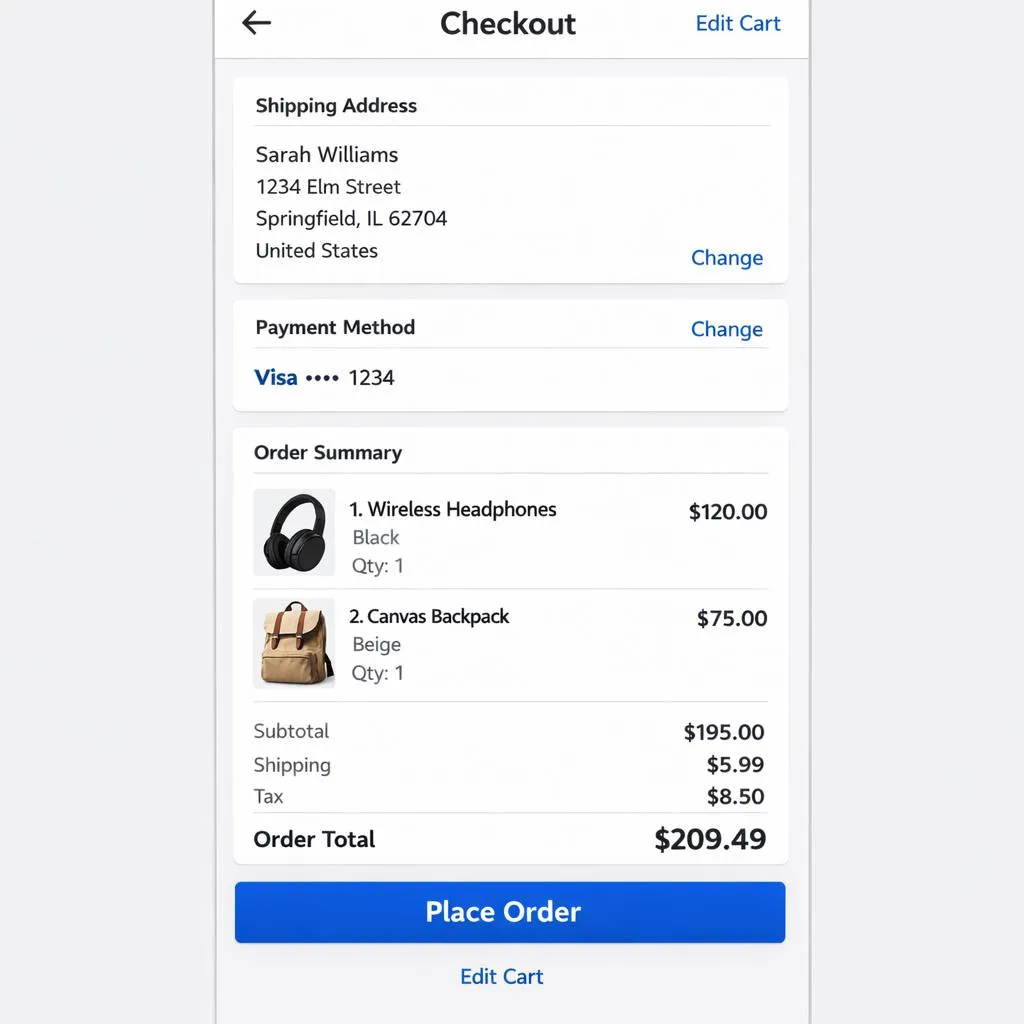
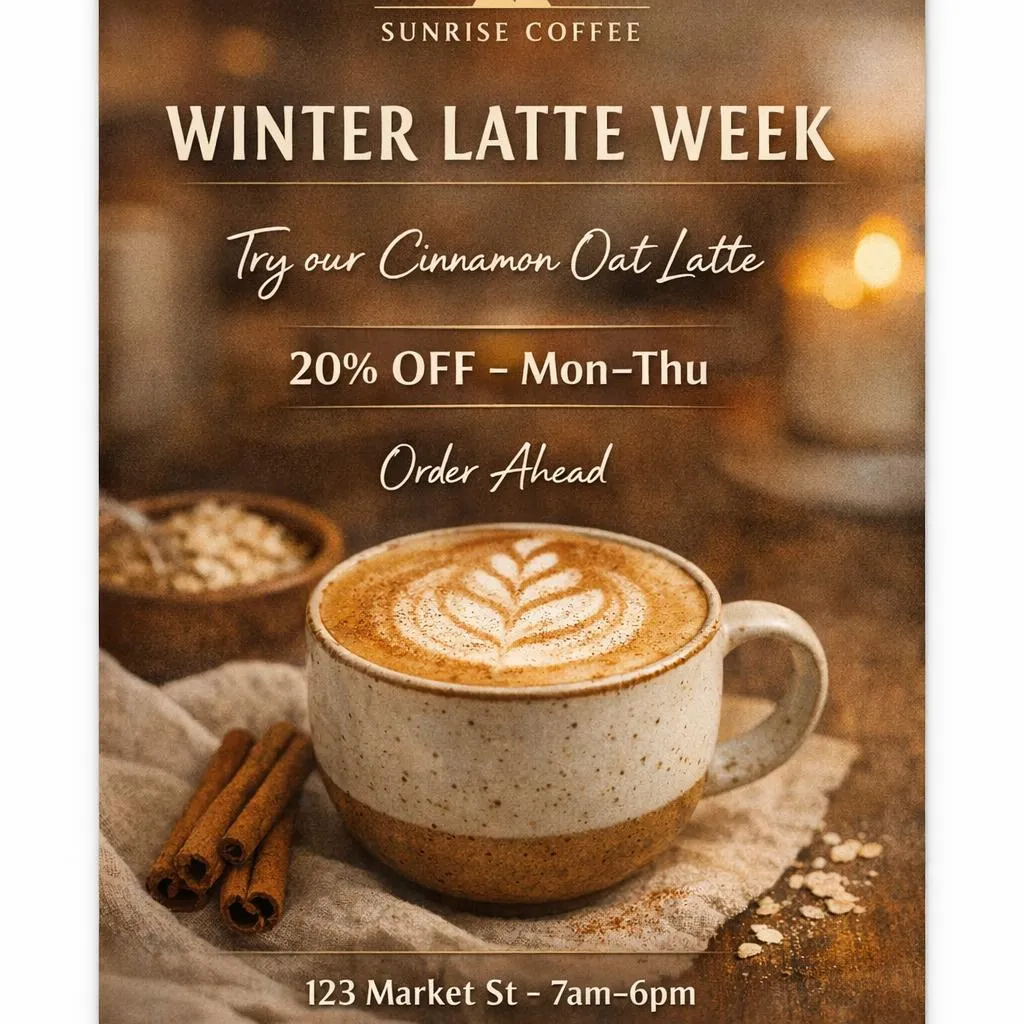

In [5]:
import udfs  # register UDFs before get_table
import pixeltable as pxt

generations = pxt.get_table('img_eval/generations')
edits = pxt.get_table('img_eval/edits')
gen_evals = pxt.get_table('img_eval/gen_evals')
edit_evals = pxt.get_table('img_eval/edit_evals')

# Checkout screen and flyer.
generations.where(generations.batch_id == 'demo_v1').select(
    generations.image, generations.case_id, generations.workflow
).collect()


In [ ]:
generations.update({'eval_ready': True}, where=generations.batch_id == 'demo_v1')

gen_evals.where(gen_evals.batch_id == 'demo_v1').select(
    gen_evals.image, gen_evals.case_id, gen_evals.verdict,
    gen_evals.scores, gen_evals.reason, gen_evals.tags,
).collect()


### A new prompt

Same grade. You insert a row.


In [ ]:
# gen_prompt goes to the image model. prompt goes to the judge. Here they match.
_ui_prompt = (
    'Generate a high-fidelity mobile checkout screen for an ecommerce app. '
    'Orientation: portrait. Include labels Checkout, Place Order, Edit Cart.'
)

generations.insert(
    case_id='ui_checkout_v2',
    batch_id='run_2',
    workflow='ui_mockup',
    gen_prompt=_ui_prompt,
    prompt=_ui_prompt,
    criteria='Mobile checkout; required labels present; clear primary call to action.',
    eval_ready=True,
)

gen_evals.where(gen_evals.case_id == 'ui_checkout_v2').select(
    gen_evals.image, gen_evals.verdict, gen_evals.scores, gen_evals.reason, gen_evals.tags
).collect()


## Recipe 2: Check the exact words

Recipe 1's verdict for the flyer already includes this check, so a flyer that is missing a required line fails. This recipe shows the check itself: the words a model read off the flyer, and which of your required lines were found. That tells you why a flyer failed.


In [9]:
# Words read off the flyer, and which required lines were found.
gen_evals.where(gen_evals.case_id == 'coffee_flyer_generation').select(
    gen_evals.extracted_text, gen_evals.text_check
).collect()


extracted_text,text_check
[],"{""pass"": false, ""extra"": [], ""missing"": [""WINTER LATTE WEEK"", ""Try our Cinnamon Oat Latte"", ""20% OFF - Mon-Thu"", ""Order Ahead"", ""123 Market St - 7am-6pm""]}"


## Recipe 3: Grade an edit

The change you asked for has to be there. The rest of the image has to stay as it was.


image,case_id,workflow
,vto_jacket_tryon,virtual_try_on
,logo_year_edit,logo_edit

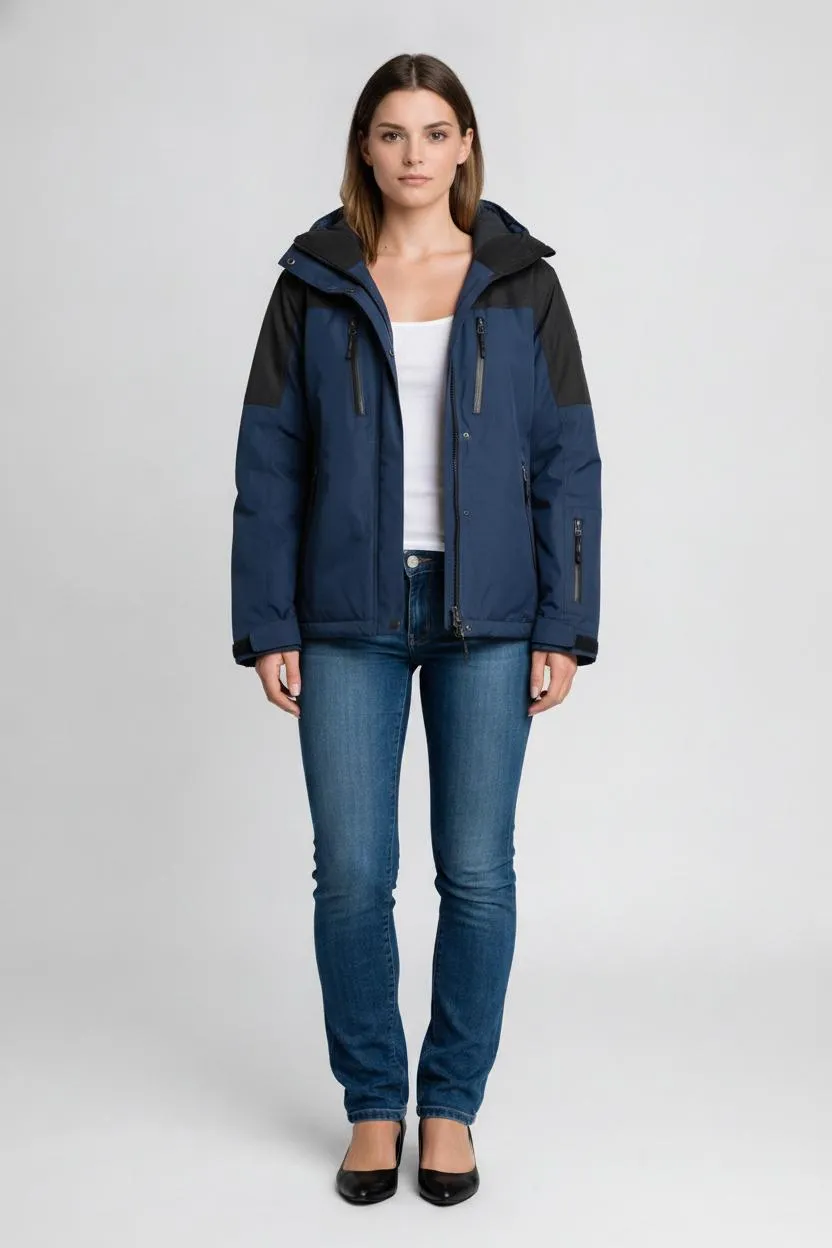
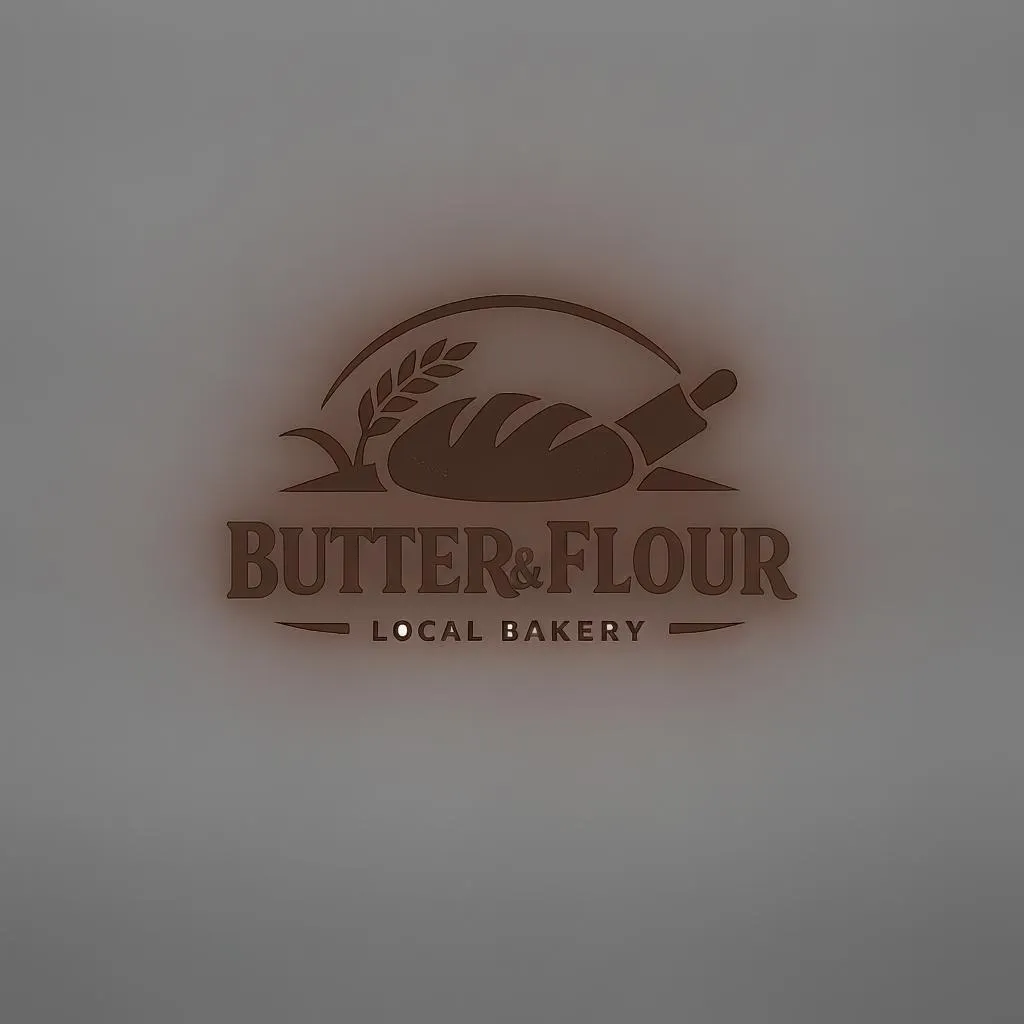

In [6]:
# Logo edit and jacket try-on.
edits.where(edits.batch_id == 'demo_v1').select(
    edits.image, edits.case_id, edits.workflow
).collect()


In [ ]:
edits.update({'eval_ready': True}, where=edits.batch_id == 'demo_v1')

edit_evals.where(edit_evals.batch_id == 'demo_v1').select(
    edit_evals.image, edit_evals.case_id, edit_evals.verdict,
    edit_evals.scores, edit_evals.reason, edit_evals.tags,
).collect()


In [ ]:
# FIELD to BUTTER, and nothing else.
_logo_prompt = (
    'Edit the logo by changing the text from FIELD to BUTTER.\n'
    'Do not change any other text, colors, shapes, or layout.'
)

edits.insert(
    case_id='logo_year_edit_live',
    batch_id='run_edit_logo',
    workflow='logo_edit',
    gen_prompt=_logo_prompt,
    prompt=_logo_prompt,
    criteria=(
        'The requested edit is applied exactly.\n'
        'All non-target content remains unchanged.\n'
        'Character style, color, and geometry remain consistent with the original.'
    ),
    ref_image='use_cases/logo_edit/assets/logo_input.png',
    eval_ready=True,
)

edit_evals.where(edit_evals.case_id == 'logo_year_edit_live').select(
    edit_evals.image, edit_evals.verdict, edit_evals.scores, edit_evals.reason, edit_evals.tags
).collect()


## Recipe 4: Two reference images

Recipe 3 has one reference image. This recipe has two. The result has to satisfy both.


In [ ]:
# Gemini, because one call takes the person and the jacket.
_vto_prompt = (
    'Put the person in the first image into the jacket shown in the second image.\n'
    "Keep the person's face, pose, body shape, and background unchanged.\n"
    "Preserve the garment's color, pattern, and key details.\n"
    'Do not add extra accessories, text, or new elements.'
)

edits.insert(
    case_id='vto_jacket_tryon_live',
    batch_id='run_edit_vto',
    workflow='virtual_try_on',
    gen_prompt=_vto_prompt,
    prompt=_vto_prompt,
    criteria=(
        'The output preserves the same person and background.\n'
        'The jacket matches the reference garment closely.\n'
        'Body shape and pose remain consistent outside normal garment effects.\n'
        'The result looks physically plausible.'
    ),
    ref_image='use_cases/virtual_try_on/assets/person.png',
    ref_image_2='use_cases/virtual_try_on/assets/garment.png',
    eval_ready=True,
)

edit_evals.where(edit_evals.case_id == 'vto_jacket_tryon_live').select(
    edit_evals.image, edit_evals.verdict, edit_evals.scores, edit_evals.reason, edit_evals.tags
).collect()


## Recipe 5: New rubric, same images

Change the rubric, then re-grade. Only the judge runs again. The images are not made again, so a re-grade makes judge calls and no image calls.


In [ ]:
# New judge call. The pictures stay.
gen_evals.recompute_columns(columns=['judge_raw'], where=gen_evals.batch_id == 'demo_v1')

gen_evals.where(gen_evals.batch_id == 'demo_v1').select(
    gen_evals.image, gen_evals.case_id, gen_evals.verdict, gen_evals.tags
).collect()


## Delete the sample rows


In [ ]:
# The four demo rows, from both tables.
generations.delete(where=generations.batch_id == 'demo_v1')
edits.delete(where=edits.batch_id == 'demo_v1')
